# Phishing Classification: Logistic Regression & Decision Tree Models
## Machine Learning Benchmarks on the PhiUSIIL Phishing URL Dataset

This notebook implements the complete machine learning modeling framework on the PhiUSIIL Phishing URL Dataset. It trains and compares:
1. **Majority Class Baseline**
2. **Logistic Regression** (L2-regularized linear model with log-scaled counts)
3. **Pruned Decision Tree** (`max_depth=5` for human interpretability and rule extraction)
4. **Full Decision Tree** (unconstrained tree classifier)

### Validation Setup:
- **Partition:** 80% train, 20% test split strictly grouped by unique `Host` to avoid cross-split host leakage.
- **Metrics Evaluated:** Accuracy, Balanced Accuracy, Precision, Recall, F1-Score, and False Positive Rate.

In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay

random_seed = 42

project_folder = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "PhiUSIIL_Phishing_URL_Dataset.csv").is_file()
)

dataset_path = project_folder / "PhiUSIIL_Phishing_URL_Dataset.csv"
output_folder = project_folder / "outputs"
figure_folder = output_folder / "figures"
figure_folder.mkdir(parents=True, exist_ok=True)

class_names = {0: "Phishing", 1: "Legitimate"}
class_order = ["Phishing", "Legitimate"]
class_colors = ["#C44E52", "#16877C"]

plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 110})
pd.set_option("display.max_columns", 15)

## 1. Data Ingestion & Pipeline Cleaning
We apply the exact deduplication and cleaning rules from `Department_Of_Phisheries.ipynb`:
- Remove exact duplicate rows
- Trim whitespace from URLs
- Remove conflicting URLs (same URL with opposite labels)
- Drop duplicated URLs
- Extract and validate hostnames
- Target definition: `IsPhishing = 1 - label` (1 = Phishing, 0 = Legitimate)


In [2]:
def read_host(url):
    try:
        return (urlsplit(str(url)).hostname or "").lower().rstrip(".")
    except ValueError:
        return ""

raw_websites = pd.read_csv(dataset_path)
print("Loaded " + f"{len(raw_websites):,}" + f" rows and {raw_websites.shape[1]} columns.")

website_data = raw_websites.drop_duplicates().copy()
website_data["URL"] = website_data["URL"].str.strip()

url_labels = website_data.groupby("URL")["label"].nunique()
conflicting_urls = url_labels[url_labels > 1].index
website_data = website_data.loc[~website_data["URL"].isin(conflicting_urls)].copy()
website_data = website_data.drop_duplicates("URL").copy()
website_data["Host"] = website_data["URL"].map(read_host)
website_data = website_data.loc[website_data["Host"].ne("")].reset_index(drop=True)

# 1 = Phishing, 0 = Legitimate for prediction modeling
website_data["Class"] = website_data["label"].map(class_names)
website_data["IsPhishing"] = 1 - website_data["label"]

print("Cleaned unique eligible URLs: " + f"{len(website_data):,}")


Loaded 235,795 rows and 56 columns.
Cleaned unique eligible URLs: 235,370


## 2. Host-Stratified Train / Test Split
To avoid data leakage, URLs belonging to the same host are never split across training and testing. We place 80% of distinct hostnames into training and 20% into testing using `random_seed=42`.


In [3]:
count_predictors = ["URLLength", "DomainLength", "NoOfSubDomain", "NoOfImage", "NoOfCSS", "NoOfJS"]
flag_predictors = ["IsHTTPS", "HasTitle", "HasFavicon", "HasSocialNet", "HasExternalFormSubmit"]
model_features = count_predictors + flag_predictors

training_hosts = website_data["Host"].drop_duplicates().sample(frac=0.80, random_state=random_seed)
training_mask = website_data["Host"].isin(training_hosts)
training_data = website_data.loc[training_mask]
test_data = website_data.loc[~training_mask]

# Unscaled inputs for Tree models
X_train_tree = training_data[model_features].astype(float)
y_train = training_data["IsPhishing"]
X_test_tree = test_data[model_features].astype(float)
y_test = test_data["IsPhishing"].to_numpy()

# Prepared inputs for Logistic Regression (log1p transform + standardization learned on training set only)
X_train_lr = X_train_tree.copy()
X_test_lr = X_test_tree.copy()

X_train_lr[count_predictors] = np.log1p(X_train_lr[count_predictors])
X_test_lr[count_predictors] = np.log1p(X_test_lr[count_predictors])

training_means = X_train_lr[count_predictors].mean()
training_spreads = X_train_lr[count_predictors].std(ddof=0).replace(0, 1)

X_train_lr[count_predictors] = (X_train_lr[count_predictors] - training_means) / training_spreads
X_test_lr[count_predictors] = (X_test_lr[count_predictors] - training_means) / training_spreads

partition_summary = pd.DataFrame([
    {"Partition": name, "URLs": len(part), "Hosts": part["Host"].nunique(),
     "PhishingShare": part["IsPhishing"].mean()}
    for name, part in [("Training", training_data), ("Test", test_data)]
])
display(partition_summary)

,Partition,URLs,Hosts,PhishingShare
0,Training,188658,176062,0.427816
1,Test,46712,44015,0.424067


## 3. Model Training (Logistic Regression & Decision Trees)
We fit:
1. **Logistic Regression:** `C=1.0`, `solver='lbfgs'`, `max_iter=1000`.
2. **Pruned Decision Tree:** `max_depth=5` to avoid overfitting and inspect clear rules.
3. **Full Decision Tree:** Unconstrained tree classifier.

In [4]:
# 1. Majority Baseline
majority_class = int(y_train.mode().iloc[0])
baseline_predictions = np.full(len(y_test), majority_class)

#2. Naive Bayes
gnb_model = GaussianNB()
gnb_model.fit(X_train_lr, y_train)
y_pred_gnb = gnb_model.predict(X_test_lr)

# 3. Decision Tree Pruned
dt_pruned = DecisionTreeClassifier(max_depth=5, random_state=random_seed)
dt_pruned.fit(X_train_tree, y_train)
y_pred_pruned = dt_pruned.predict(X_test_tree)

# 4. Logistic Regression
lr_model = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=random_seed)
lr_model.fit(X_train_lr, y_train)
y_pred_lr = lr_model.predict(X_test_lr)

# 5. Decision Tree
dt_full = DecisionTreeClassifier(random_state=random_seed)
dt_full.fit(X_train_tree, y_train)
y_pred_full = dt_full.predict(X_test_tree)


print("All classification models trained successfully.")

All classification models trained successfully.


## 4. Classification Reports
Detailed evaluation metrics (Precision, Recall, F1-Score, Support) across all models:
- **Class 0:** Legitimate
- **Class 1:** Phishing

In [5]:
target_names = ["Legitimate (0)", "Phishing (1)"]

print("=========================================================")
print("CLASSIFICATION REPORT: GAUSSIAN NAIVE BAYES")
print("=========================================================")
print(classification_report(y_test, y_pred_gnb, target_names=target_names, digits=4))

print("=========================================================")
print("CLASSIFICATION REPORT: PRUNED DECISION TREE (max_depth=5)")
print("=========================================================")
print(classification_report(y_test, y_pred_pruned, target_names=target_names, digits=4))

print("=========================================================")
print("CLASSIFICATION REPORT: LOGISTIC REGRESSION")
print("=========================================================")
print(classification_report(y_test, y_pred_lr, target_names=target_names, digits=4))

print("=========================================================")
print("CLASSIFICATION REPORT: FULL DECISION TREE")
print("=========================================================")
print(classification_report(y_test, y_pred_full, target_names=target_names, digits=4))


CLASSIFICATION REPORT: GAUSSIAN NAIVE BAYES
                precision    recall  f1-score   support

Legitimate (0)     0.9489    0.9976    0.9726     26903
  Phishing (1)     0.9965    0.9270    0.9605     19809

      accuracy                         0.9677     46712
     macro avg     0.9727    0.9623    0.9666     46712
  weighted avg     0.9691    0.9677    0.9675     46712

CLASSIFICATION REPORT: PRUNED DECISION TREE (max_depth=5)
                precision    recall  f1-score   support

Legitimate (0)     0.9919    0.9806    0.9862     26903
  Phishing (1)     0.9741    0.9891    0.9815     19809

      accuracy                         0.9842     46712
     macro avg     0.9830    0.9849    0.9839     46712
  weighted avg     0.9843    0.9842    0.9842     46712

CLASSIFICATION REPORT: LOGISTIC REGRESSION
                precision    recall  f1-score   support

Legitimate (0)     0.9973    0.9979    0.9976     26903
  Phishing (1)     0.9972    0.9963    0.9967     19809

      a

## 5. Model Comparison Summary Table
Comparing all models against the Majority Baseline using the standardized metrics table.

In [6]:
model_rows = []

for model_name, predictions in [
    ("Majority baseline", baseline_predictions),
    ("Gaussian Naive Bayes", y_pred_gnb),
    ("Decision Tree (max_depth=5)", y_pred_pruned),
    ("Logistic regression", y_pred_lr),
    ("Decision Tree (full)", y_pred_full),
]:
    true_positive = int(((predictions == 1) & (y_test == 1)).sum())
    false_positive = int(((predictions == 1) & (y_test == 0)).sum())
    true_negative = int(((predictions == 0) & (y_test == 0)).sum())
    false_negative = int(((predictions == 0) & (y_test == 1)).sum())

    precision = true_positive / (true_positive + false_positive) if (true_positive + false_positive) else 0.0
    recall = true_positive / (true_positive + false_negative)
    false_positive_rate = false_positive / (false_positive + true_negative)
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

    model_rows.append({
        "Model": model_name,
        "Accuracy": (true_positive + true_negative) / len(y_test),
        "BalancedAccuracy": (recall + 1 - false_positive_rate) / 2,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FalsePositiveRate": false_positive_rate,
        "TruePositive": true_positive,
        "FalsePositive": false_positive,
        "TrueNegative": true_negative,
        "FalseNegative": false_negative,
    })

comparison_df = pd.DataFrame(model_rows).round(4)
display(comparison_df)

,Model,Accuracy,BalancedAccuracy,Precision,Recall,F1,FalsePositiveRate,TruePositive,FalsePositive,TrueNegative,FalseNegative
0,Majority baseline,0.5759,0.5000,0.0000,0.0000,0.0000,0.0000,0,0,26903,19809
1,Gaussian Naive Bayes,0.9677,0.9623,0.9965,0.9270,0.9605,0.0024,18363,65,26838,1446
2,Decision Tree (max_depth=5),0.9842,0.9849,0.9741,0.9891,0.9815,0.0194,19593,521,26382,216
3,Logistic regression,0.9972,0.9971,0.9972,0.9963,0.9967,0.0021,19736,56,26847,73
4,Decision Tree (full),0.9974,0.9973,0.9970,0.9968,0.9969,0.0022,19746,59,26844,63


## 6. Feature Importances & Visualizing Decision Rules
Decision trees allow direct extraction of Gini feature importances to show which webpage indicators drive classification.


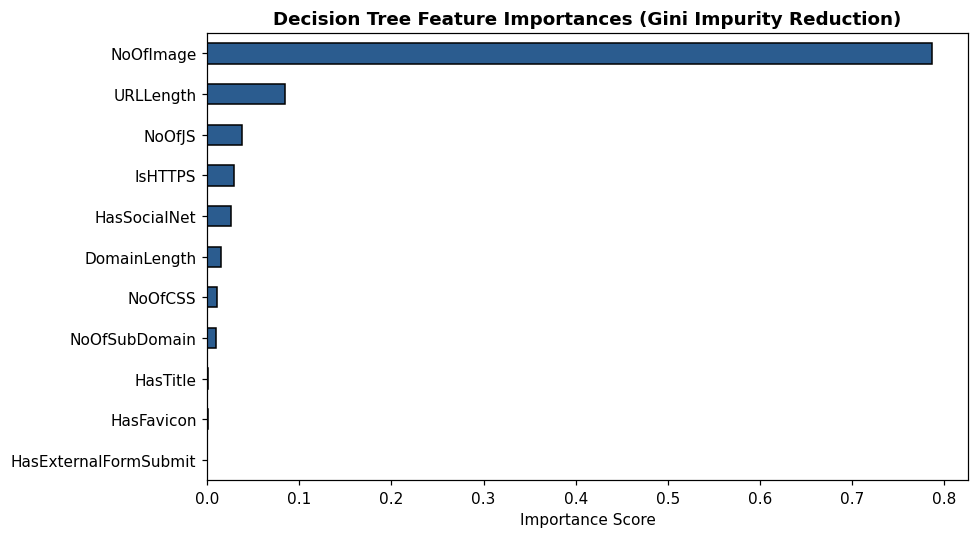

Top 5 Most Informative Features:


NoOfImage       0.786279
URLLength       0.084651
NoOfJS          0.038156
IsHTTPS         0.028638
HasSocialNet    0.025304
dtype: float64

In [7]:
importances = pd.Series(dt_full.feature_importances_, index=model_features).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
importances.plot(kind="barh", ax=ax, color="#2b5c8f", edgecolor="black")
ax.set_title("Decision Tree Feature Importances (Gini Impurity Reduction)", fontsize=12, fontweight="bold")
ax.set_xlabel("Importance Score")
plt.tight_layout()
plt.savefig(figure_folder / "decision_tree_feature_importances.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 5 Most Informative Features:")
display(importances.sort_values(ascending=False).head(5))


## 7. Confusion Matrix Visualizations
Visualizing confusion matrices for Logistic Regression, Full Decision Tree, and Pruned Decision Tree.

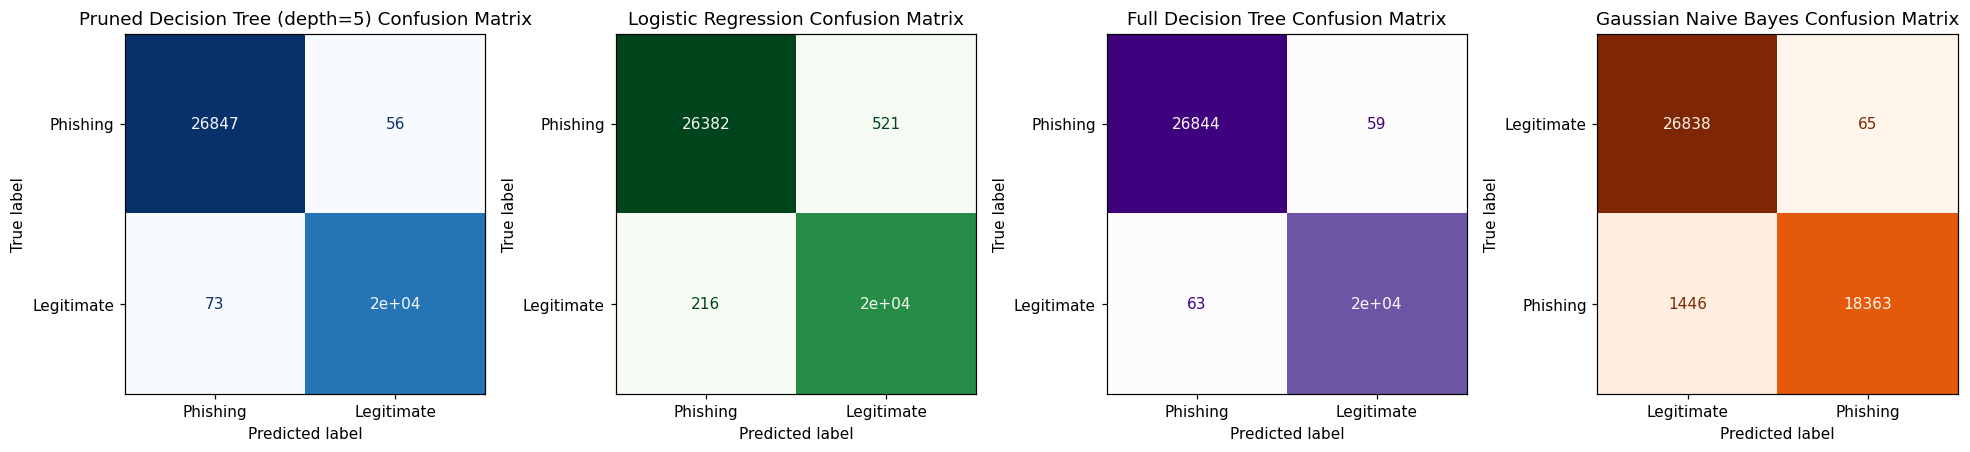

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_pruned,
    display_labels=class_order,
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)
axes[0].set_title("Pruned Decision Tree (depth=5) Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr,
    display_labels=class_order,
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[1].set_title("Logistic Regression Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_full,
    display_labels=class_order,
    cmap="Purples",
    ax=axes[2],
    colorbar=False
)
axes[2].set_title("Full Decision Tree Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_gnb,
    display_labels=["Legitimate", "Phishing"],
    cmap="Oranges",
    ax=axes[3],
    colorbar=False
)

axes[3].set_title("Gaussian Naive Bayes Confusion Matrix")

plt.tight_layout()
plt.savefig(figure_folder / "all_models_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Pruned Decision Tree Structure (First 3 Levels)
Below we plot the top branch decisions of the tree to see the exact decision boundaries learned from the URL and webpage features.


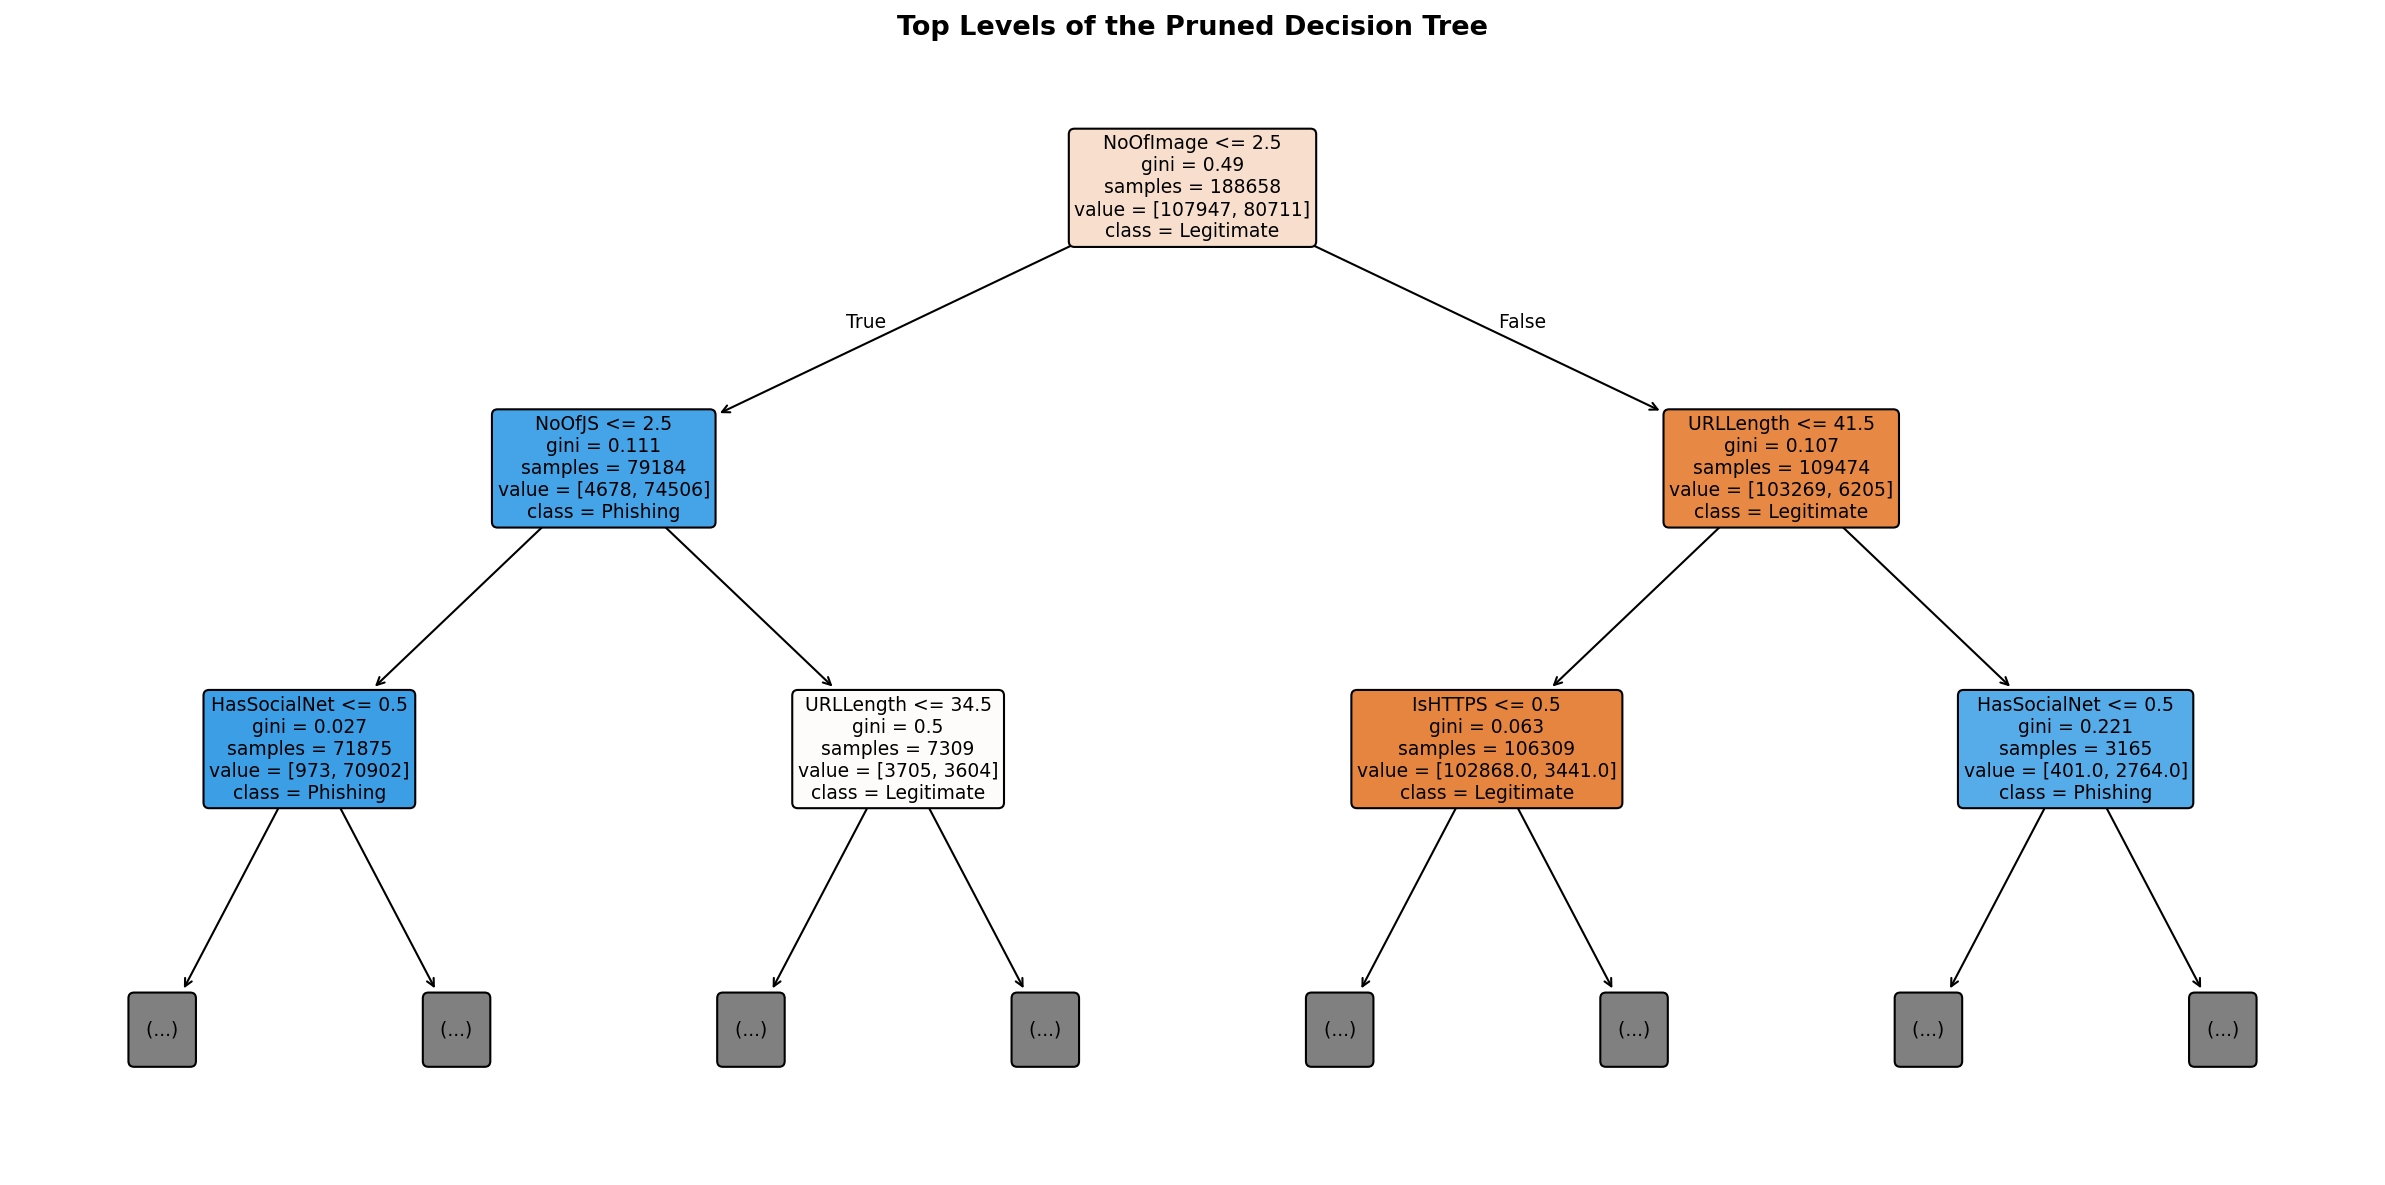

In [9]:
fig, ax = plt.subplots(figsize=(16, 8), dpi=150)
plot_tree(
    dt_pruned,
    max_depth=2,
    feature_names=model_features,
    class_names=["Legitimate", "Phishing"],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)
ax.set_title("Top Levels of the Pruned Decision Tree", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(figure_folder / "decision_tree_tree_structure.png", dpi=150, bbox_inches="tight")
plt.show()



## 9. ROC-AUC Curve Comparison

The ROC curves compare Logistic Regression, the Pruned Decision Tree, the Full Decision Tree, and Gaussian Naive Bayes on the held-out test set. The True Positive Rate measures how many phishing URLs are correctly identified, while the False Positive Rate measures how many legitimate URLs are incorrectly flagged.

The Area Under the Curve (AUC) summarizes each model's ability to distinguish between phishing and legitimate URLs. A higher AUC generally indicates better discriminatory performance. The results are interpreted alongside accuracy, precision, recall, and the confusion matrices to support model selection.


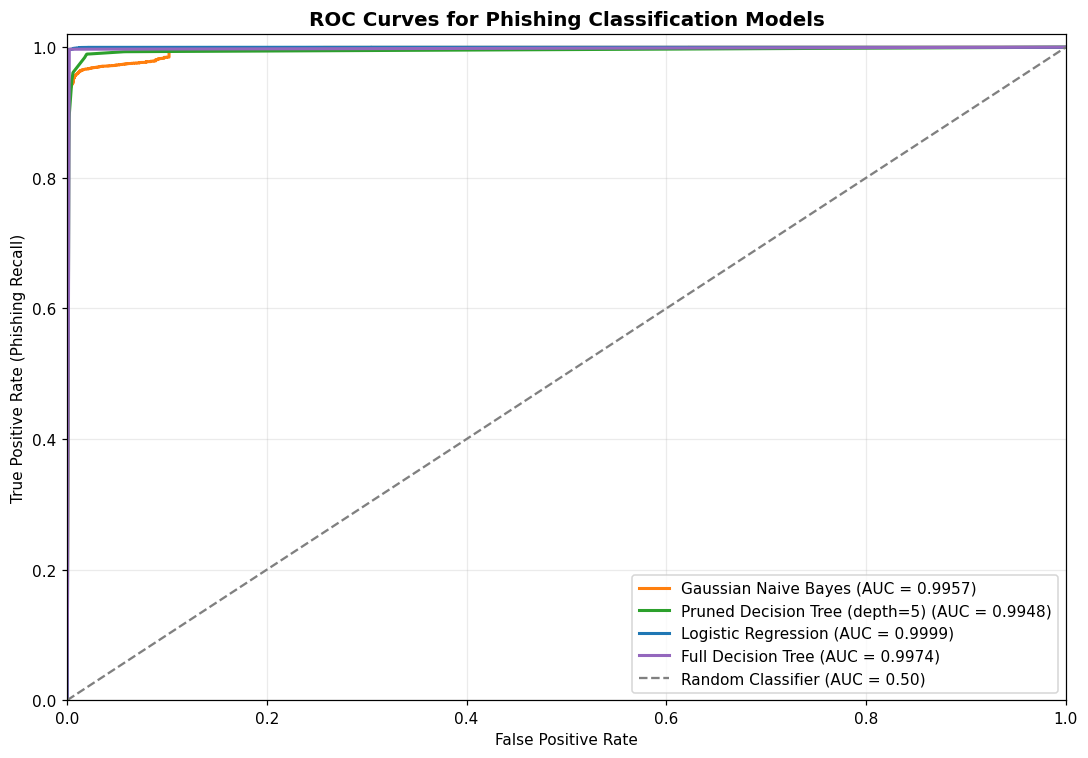

In [10]:
roc_models = {
    "Gaussian Naive Bayes": (gnb_model, X_test_lr, "#ff7f0e"),
    "Pruned Decision Tree (depth=5)": (dt_pruned, X_test_tree, "#2ca02c"),
    "Logistic Regression": (lr_model, X_test_lr, "#1f77b4"),
    "Full Decision Tree": (dt_full, X_test_tree, "#9467bd")
}

fig, ax = plt.subplots(figsize=(10, 7))

for model_name, (model, X_test, color) in roc_models.items():
    # Probability of class 1 = Phishing
    y_score = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_score, pos_label=1)
    roc_auc = roc_auc_score(y_test, y_score)

    ax.plot(
        fpr,
        tpr,
        color=color,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.4f})"
    )

# Random classifier reference line
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.50)"
)

ax.set_title("ROC Curves for Phishing Classification Models",
             fontsize=13, fontweight="bold")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Phishing Recall)")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.legend(loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    figure_folder / "all_models_roc_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
